# XGBoost — parâmetros por F1 e threshold por GridSearchCV

F1 seleciona parâmetros e limiar, acompanhando Recall e Precision; AP/AUPRC é diagnóstico.
Na CV de parâmetros usa-se uma referência comum 0,50. O limiar operacional é escolhido
na grade interna, não imposto. A ordem é busca de parâmetros → threshold → validação.
Nenhum TEST é pontuado, e os dados já foram explorados historicamente.

Treino: `python -m fraud_detection.classification_search --family xgboost`.
Estatísticas completas: [xgboost_model_metrics.ipynb](xgboost_model_metrics.ipynb).
EXECUTAR_BUSCA=False lê relatórios; True executa em uma saída ainda não concluída.

In [1]:
# A busca só é executada quando explicitamente ativada.
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from fraud_detection.data import load_config
from fraud_detection.classification_search import run
from fraud_detection.reporting import readable_table

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists(): ROOT = ROOT.parent
EXECUTAR_BUSCA = False
OUTPUT = ROOT
config = load_config(ROOT / "configs/experiment.yaml")
features = load_config(ROOT / "configs/ablation.yaml")
settings = load_config(ROOT / "configs/xgboost_f1_threshold.yaml")
if EXECUTAR_BUSCA:
    run(config, features, settings, OUTPUT)
PREFIX = settings["experiment_name"]
METRICS, FIGURES = OUTPUT / "reports/metrics", OUTPUT / "reports/figures"
manifest_path = OUTPUT / "reports/experiments" / f"{PREFIX}_manifest.json"
if not manifest_path.exists(): raise FileNotFoundError("Execute python -m fraud_detection.classification_search.")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
assert not manifest["test_evaluated"] and not manifest["validation_used_for_selection"]
def table(name): return pd.read_csv(METRICS / f"{PREFIX}_{name}.csv")
def figure(name): display(Image(filename=str(FIGURES / f"{PREFIX}_{name}.png"), width=1100))


## 1. Grade e três períodos separados

A grade pesquisa learning_rate, max_depth, n_estimators, reg_alpha (L1) e
reg_lambda (L2). Scaling, seleção de features e SMOTE ficam dentro do treino.
Os modelos dos folds usados para AP não veem a janela de threshold. O pipeline
ajustado antes dessa janela permanece congelado depois de escolher o limiar.

In [2]:
display({key: manifest[key] for key in ["best_params", "best_cv_score", "threshold", "search_fit_rows", "search_fit_time_max",
    "threshold_rows", "threshold_time_min", "threshold_time_max", "validation_rows", "validation_time_min",
    "combinations", "executed_grid_fits", "reused_grid_fits"]})
display(manifest["settings"]["param_grid"])


{'best_params': {'learning_rate': 0.01,
  'max_depth': 4,
  'n_estimators': 200,
  'reg_alpha': 0.0,
  'reg_lambda': 1.0},
 'best_cv_score': 0.8245342575973262,
 'threshold': 0.6,
 'search_fit_rows': 119920,
 'search_fit_time_max': 75810.0,
 'threshold_rows': 36213,
 'threshold_time_min': 75811.0,
 'threshold_time_max': 108793.0,
 'validation_rows': 54159,
 'validation_time_min': 108799.0,
 'combinations': 162,
 'executed_grid_fits': 0,
 'reused_grid_fits': 324}

{'max_depth': [3, 4, 6],
 'n_estimators': [100, 200, 400],
 'reg_alpha': [0.0, 1.0],
 'reg_lambda': [0.0, 1.0, 5.0],
 'learning_rate': [0.01, 0.05, 0.1]}

## 2. GridSearchCV e seleção por F1

Média e desvio de F1 usam somente os dois folds anteriores ao threshold.
Os ranks são recalculados nesses folds. O gráfico é um perfil da melhor F1 por
valor; outros parâmetros podem variar, então não é uma medida de efeito isolado.

,rank_test_f1,param_model__learning_rate,param_model__max_depth,param_model__n_estimators,param_model__reg_alpha,param_model__reg_lambda,mean_test_f1,std_test_f1,mean_test_recall,mean_test_precision,mean_test_average_precision
0,1,0.0100,4,200,0.0000,1.0000,0.8245,0.0166,0.7533,0.9108,0.7602
1,2,0.0100,4,200,1.0000,5.0000,0.8232,0.0179,0.7472,0.9165,0.7635
2,3,0.0100,4,200,1.0000,0.0000,0.8219,0.0192,0.7411,0.9226,0.7600
3,4,0.0100,4,200,0.0000,5.0000,0.8206,0.0206,0.7472,0.9099,0.7648
4,4,0.0100,4,200,1.0000,1.0000,0.8206,0.0206,0.7472,0.9099,0.7605
5,6,0.0100,4,200,0.0000,0.0000,0.8192,0.0219,0.7411,0.9157,0.7702
6,7,0.0100,3,200,0.0000,0.0000,0.8152,0.0072,0.7448,0.9004,0.7465
7,8,0.0100,3,100,1.0000,0.0000,0.8148,0.0121,0.7242,0.9316,0.7731
8,8,0.0100,3,100,1.0000,1.0000,0.8148,0.0121,0.7242,0.9316,0.7731
9,10,0.0100,3,200,0.0000,1.0000,0.8141,0.0007,0.7448,0.8975,0.7686


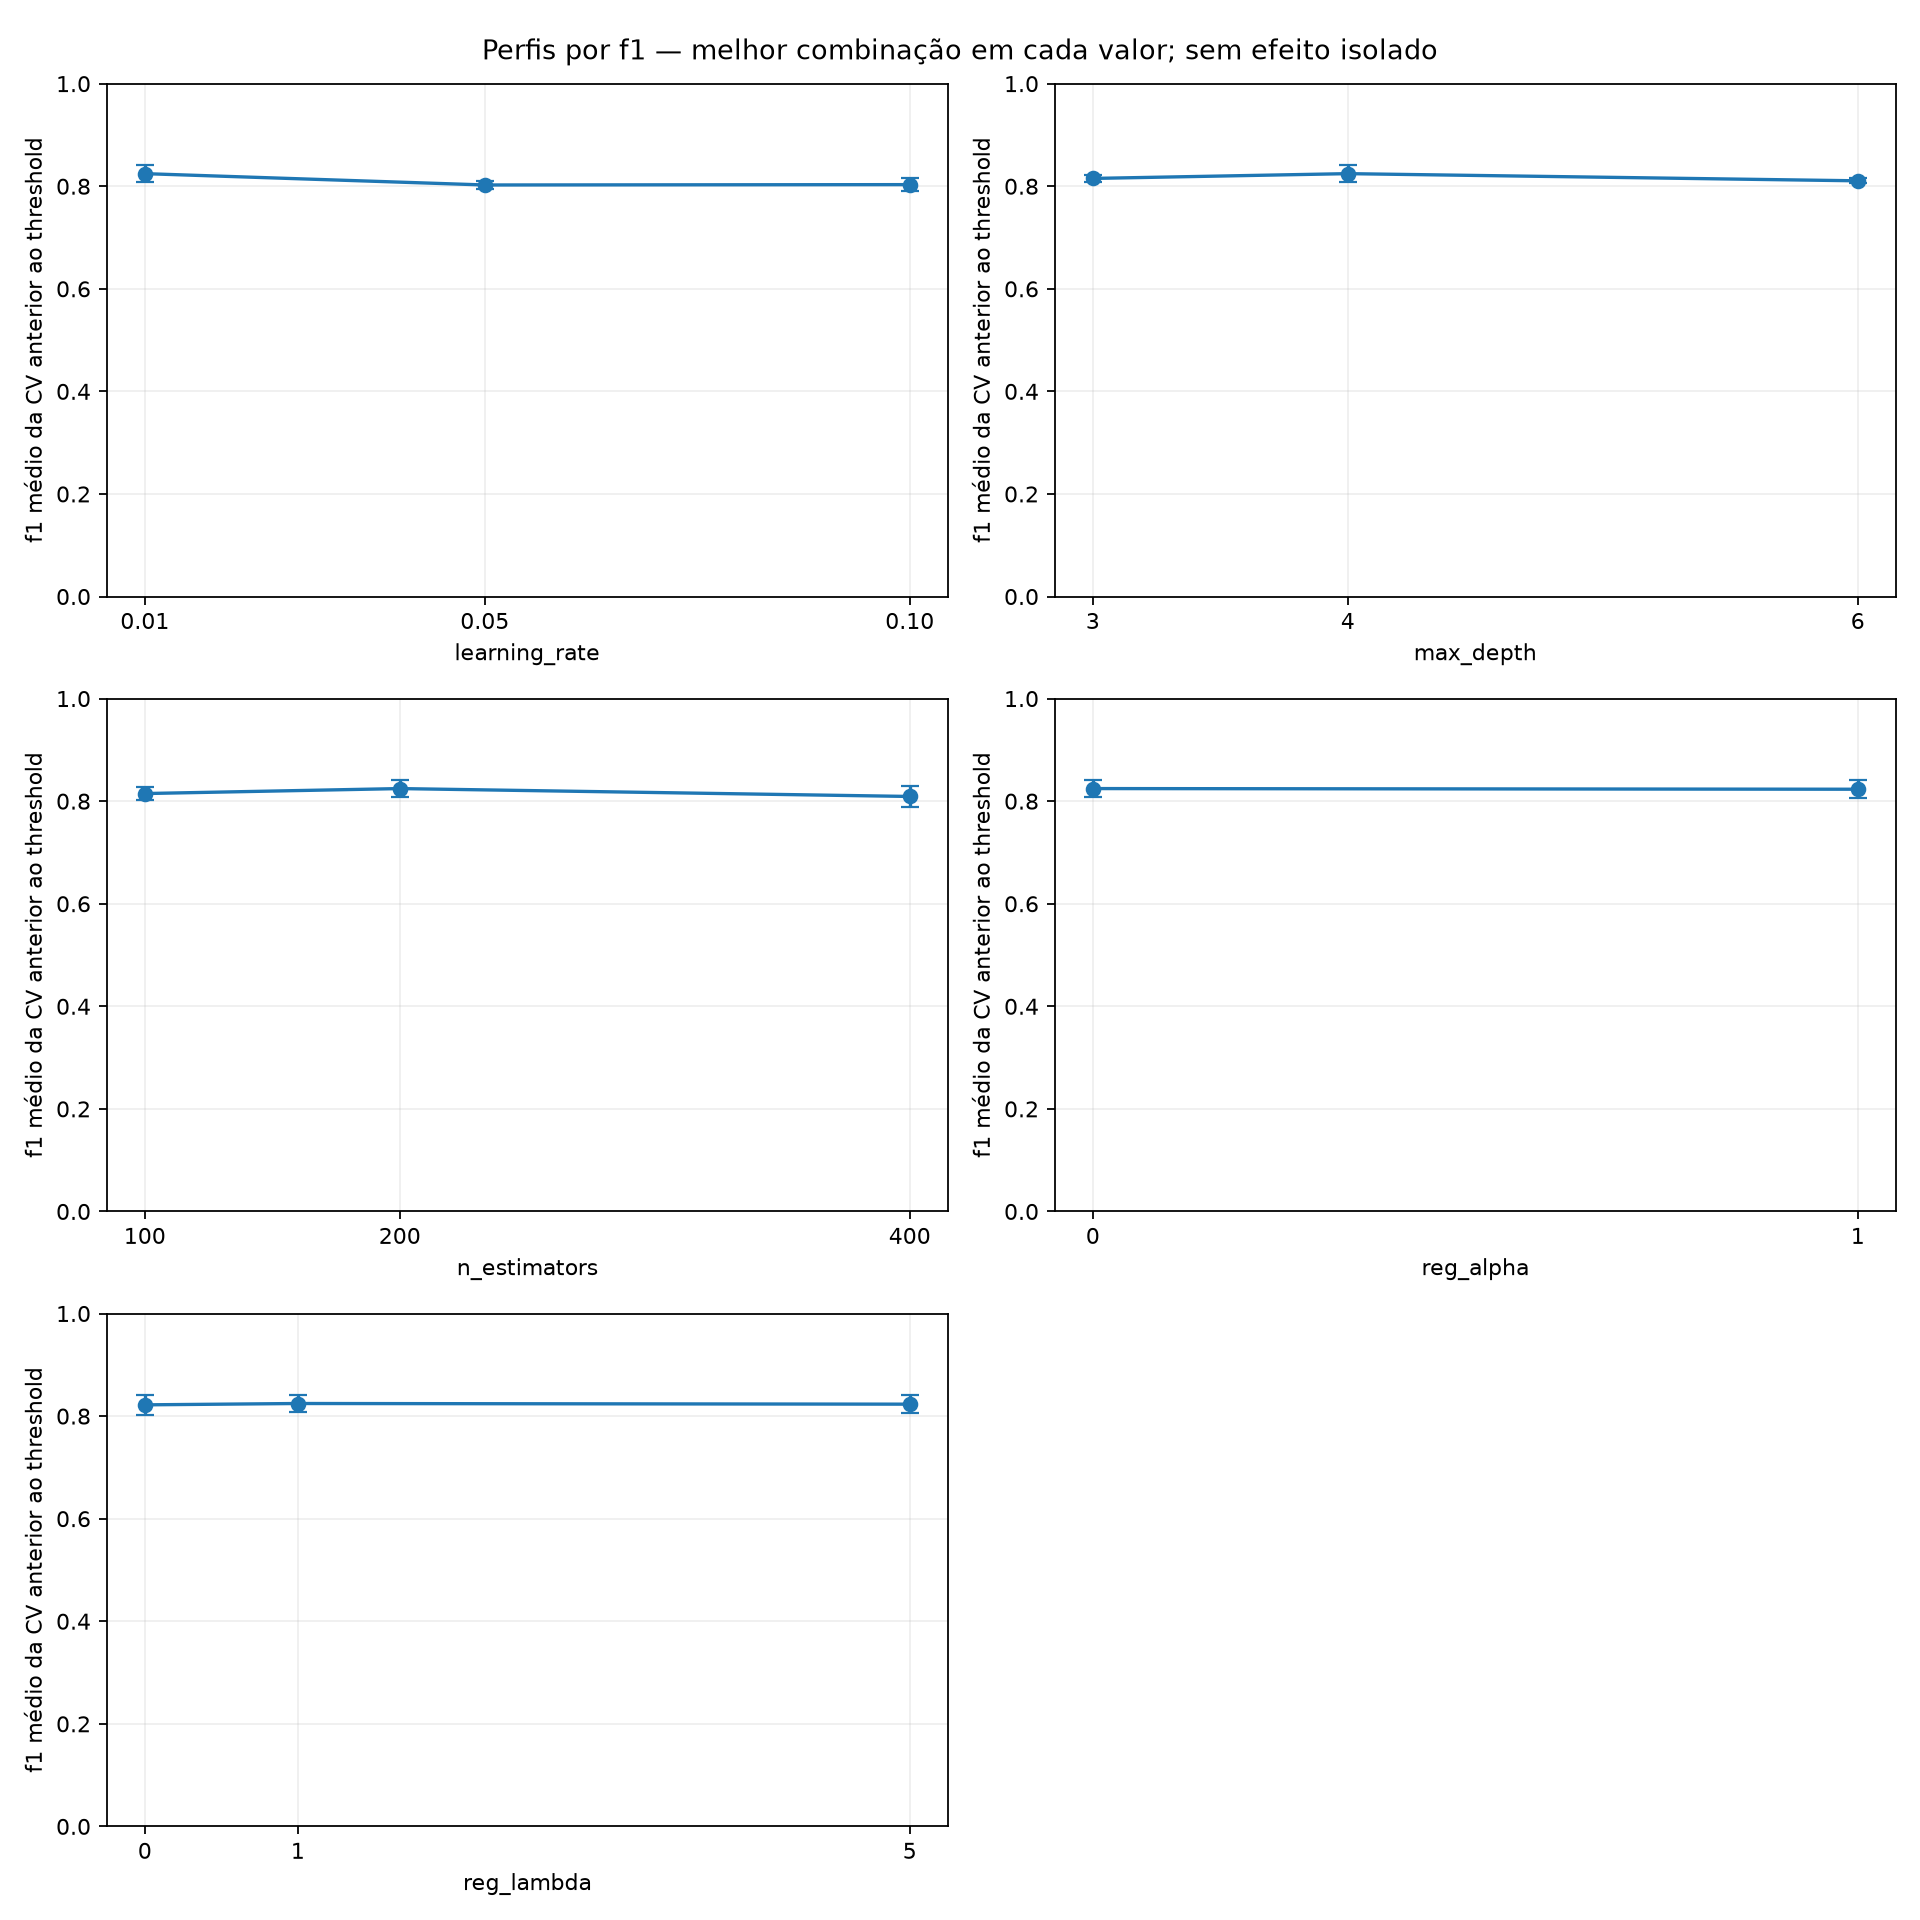

In [3]:
grid = table("results").sort_values("rank_test_f1")
columns = ["rank_test_f1", "param_model__learning_rate", "param_model__max_depth",
           "param_model__n_estimators", "param_model__reg_alpha", "param_model__reg_lambda",
           "mean_test_f1", "std_test_f1", "mean_test_recall", "mean_test_precision", "mean_test_average_precision"]
display(grid[columns].head(12).style.format(precision=4))
figure("parameters")


## 3. GridSearchCV do threshold

AP usa scores contínuos e não muda com o threshold. A grade do limiar usa F1,
com Precision/Recall complementares. FrozenEstimator impede refits. A janela
reservada escolhe o limiar; a validação seguinte fica fora de ambas as escolhas.

,Limiar de alerta,F1 (%),Recall (%),Precision (%),AP (score),TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas
0,"0,0000",0.50%,100.00%,0.25%,"0,8173",90,36.123,0
1,"0,0010",0.50%,100.00%,0.25%,"0,8173",90,36.123,0
2,"0,0050",0.50%,100.00%,0.25%,"0,8173",90,36.123,0
3,"0,0100",0.50%,100.00%,0.25%,"0,8173",90,36.123,0
4,"0,0200",1.49%,97.78%,0.75%,"0,8173",88,11.629,2
5,"0,0300",3.92%,96.67%,2.00%,"0,8173",87,4.261,3
6,"0,0500",10.27%,94.44%,5.43%,"0,8173",85,1.480,5
7,"0,0750",18.59%,92.22%,10.34%,"0,8173",83,720,7
8,"0,1000",29.23%,92.22%,17.36%,"0,8173",83,395,7
9,"0,1250",34.32%,90.00%,21.20%,"0,8173",81,301,9


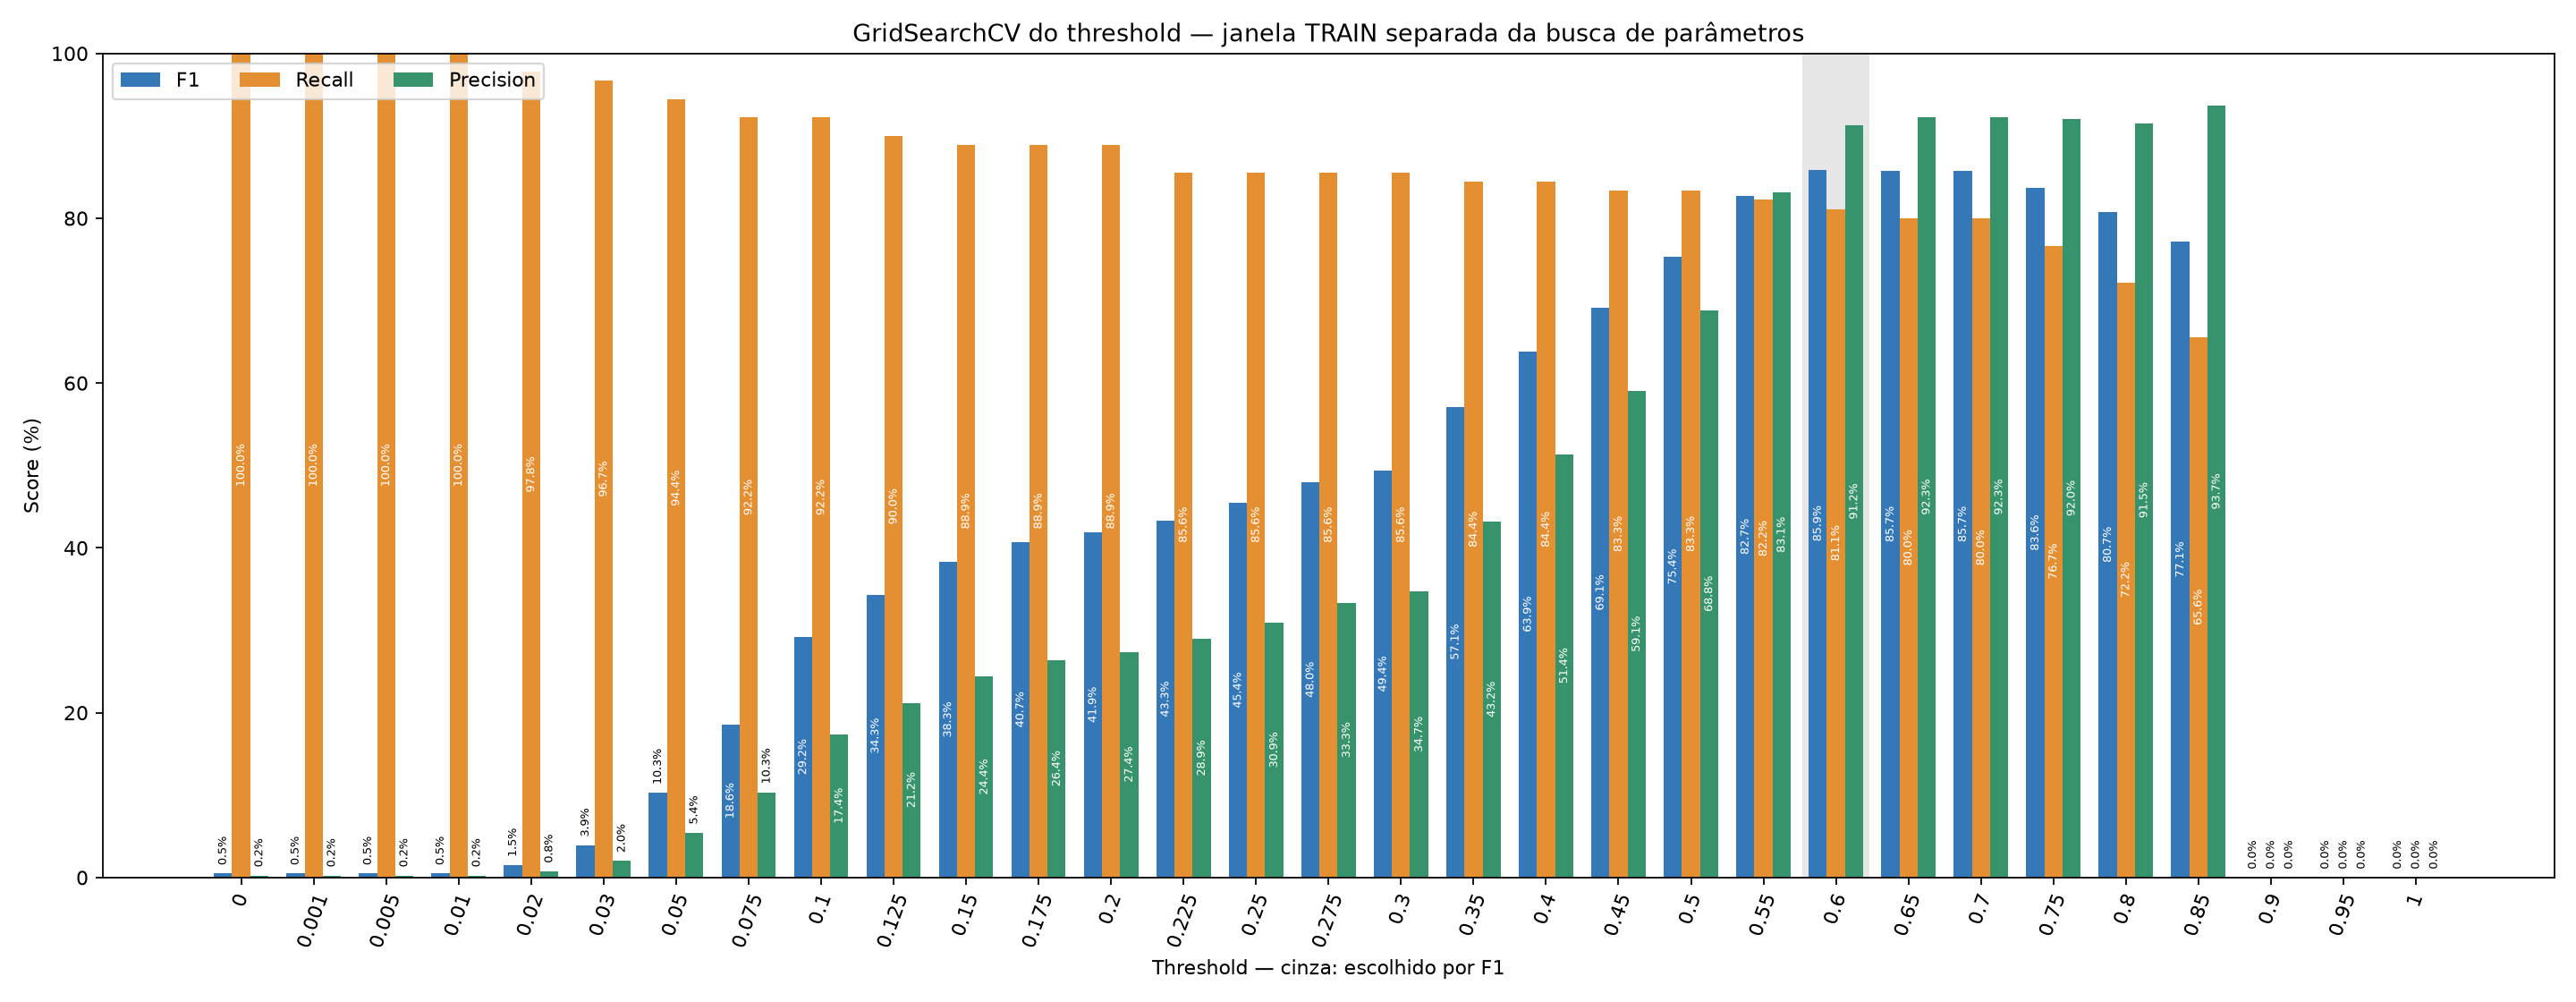

**Threshold escolhido na janela interna: 0.6000.**

In [4]:
thresholds = table("thresholds")
display(readable_table(thresholds[["threshold", "f1", "recall", "precision", "average_precision", "tp", "fp", "fn"]]))
figure("thresholds")
display(Markdown(f"**Threshold escolhido na janela interna: {manifest['threshold']:.4f}.**"))


## 4. Validação após congelar parâmetros e threshold

O mesmo pipeline usado na janela de threshold é aplicado à validação posterior,
sem refit ou calibração. Não é TEST. O histórico já explorou esses períodos;
confirmação independente exige dados novos. O notebook de estatísticas apresenta
matriz, PR/AP, ROC, calibração, métricas por classe, importâncias e erros por faixa.

,Receita,Origem,AP (score),F1 (%),Recall (%),Precision (%),ROC-AUC (score),Balanced Accuracy (%),Especificidade (%),Log Loss,Brier score,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas,Limiar de alerta,alerts,Taxa de alertas (%),accuracy,negative_predictive_value,false_positive_rate,false_negative_rate,false_discovery_rate,false_omission_rate,prevalence,mcc,cohen_kappa,pr_auc_trapezoid,rows,positives,negatives
0,XGBoost f1 + SMOTE,Validação temporal TRAIN posterior ao ajuste do threshold; histórico explorado,"0,6958",68.00%,77.27%,60.71%,"0,9683",88.62%,99.96%,"0,0303","0,0021",54.093,22,10,34,"0,6000",56,0.10%,"0,9994","0,9998","0,0004","0,2273","0,3929","0,0002","0,0008","0,6847","0,6797","0,6903",54.159,44,54.115


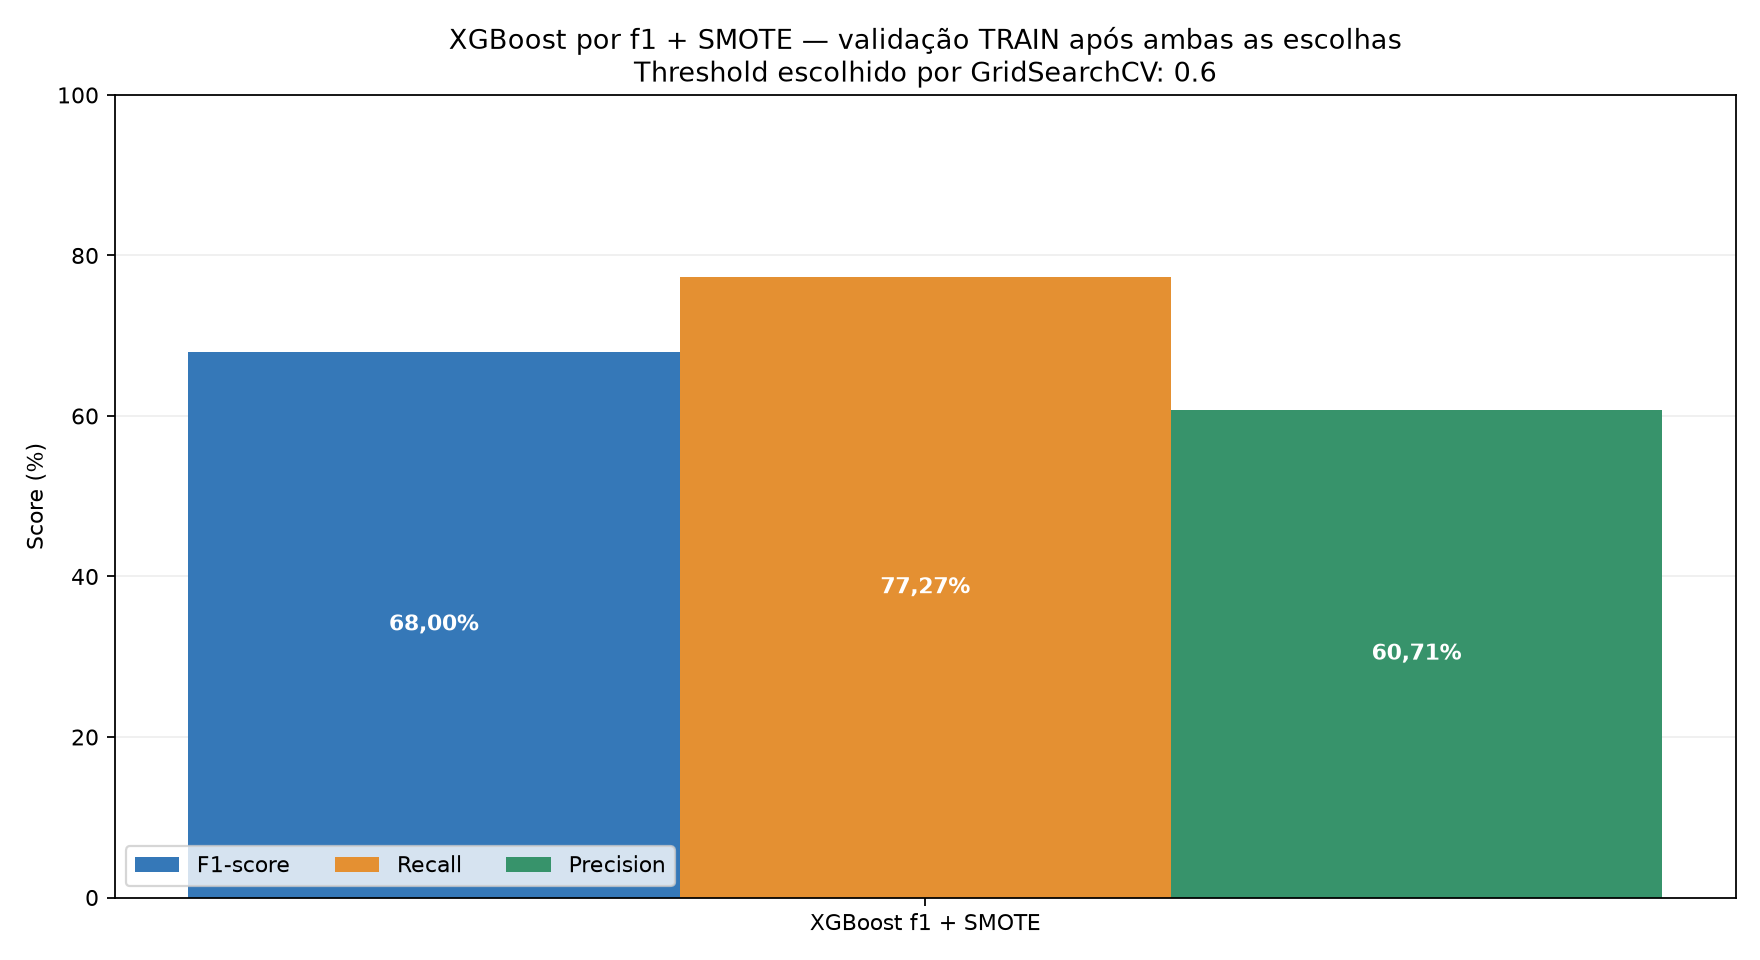

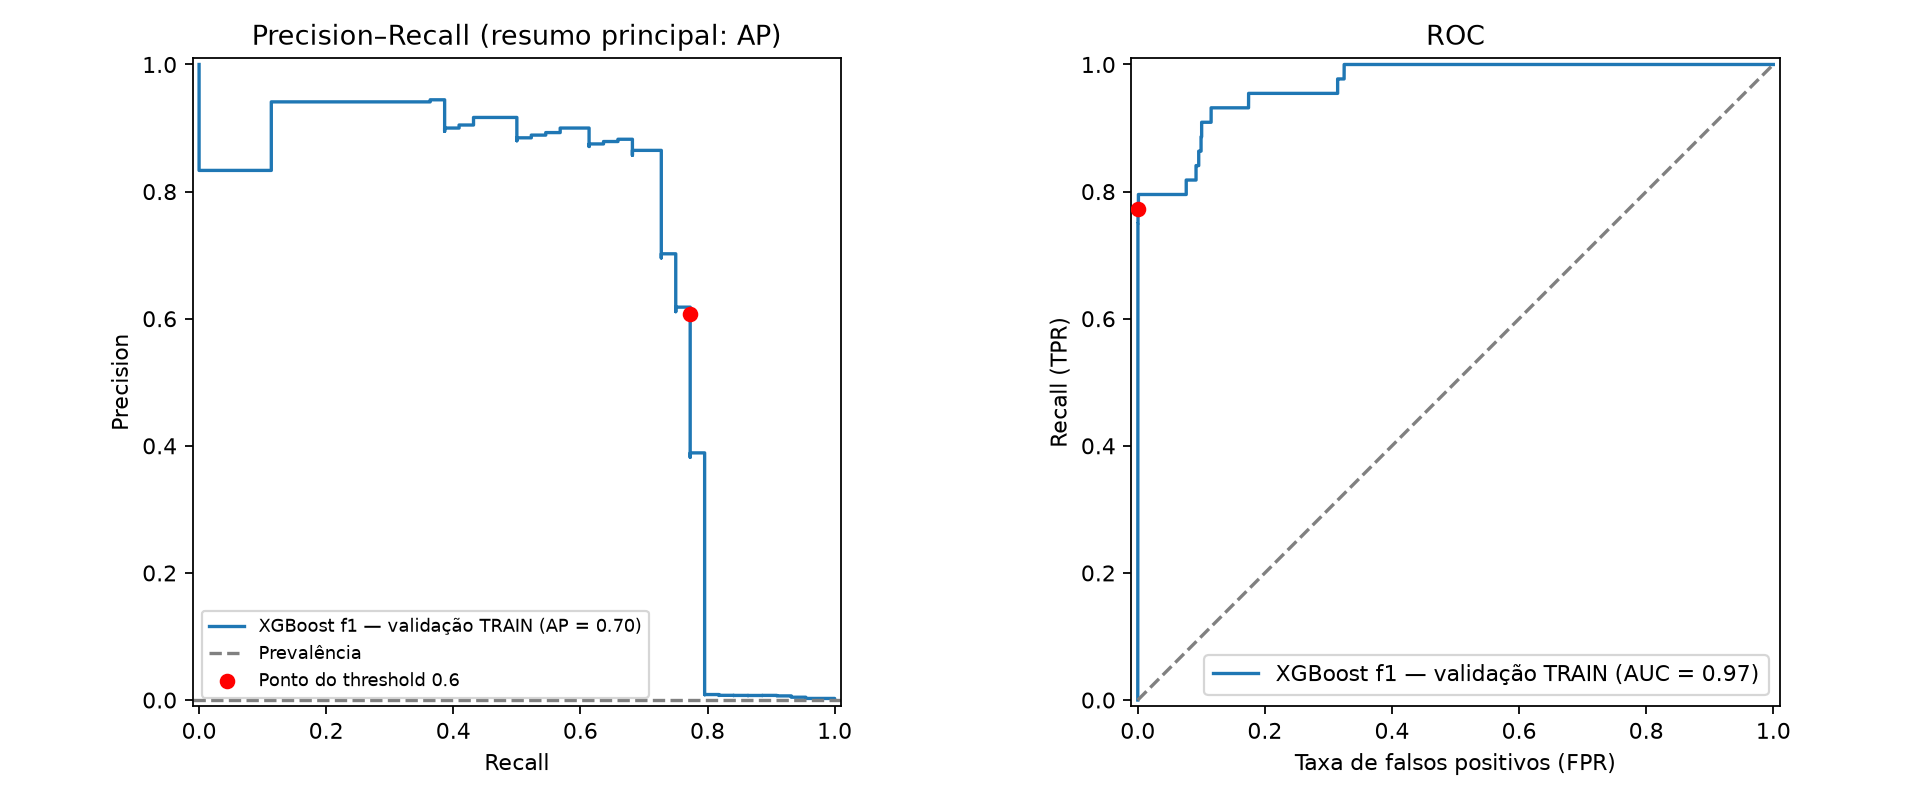

['F1 equilibra Precision e Recall; AP permanece diagnóstico quando F1 é a métrica de seleção.',
 'Seleção usa somente os folds anteriores à janela de threshold; limiar final é ajustado por F1 nessa janela.',
 'Na CV de parâmetros, F1/Recall/Precision usam a referência comum 0,50; o limiar operacional não fica fixado nesse valor.',
 'Validação TRAIN ficou fora de ambas as escolhas nesta rodada, mas o histórico já explorou esses dados.',
 'O mesmo pipeline congelado usado no threshold é aplicado à validação, sem refit posterior ou calibração.',
 'Não houve novo TEST; confirmação independente exige dados novos.']

In [5]:
display(readable_table(table("validation")))
figure("model_f1_recall_precision")
figure("pr_roc")
display(manifest["limitations"])
